# Tuần 0 — Làm quen công cụ
**Tài liệu tự học độc lập, dùng chung cho ba hướng đồ án** (NLP với TF-IDF · Máy học trên dữ liệu dạng bảng · NLP với Word2Vec và LSTM) · thời lượng: **1–1,5 giờ** (phần D thêm khoảng 30 phút, chỉ dành cho Word2Vec–LSTM) · **không chấm điểm, không nộp**.

**Mục đích.** Làm quen với môi trường notebook, thao tác dữ liệu nhỏ, cách tổ chức quy trình học/đánh giá và cách đọc kích thước tensor. Ví dụ và dữ liệu được tạo ngay trong notebook; không cần mở hoặc hoàn thành một trong ba đồ án mới làm được tuần 0. Các liên hệ dưới đây chỉ giúp chọn phần phù hợp, không phải điều kiện tiên quyết.

| Phần | Học để làm gì? | Liên hệ với ba hướng đồ án |
|---|---|---|
| **A. Colab** | Chạy cell, khởi động lại phiên, xem thư viện, đọc/ghi tệp | Nền tảng chung cho cả ba |
| **B. pandas và vẽ hình** | Đọc bảng, tính thống kê theo nhóm, lấy mẫu tái lập, vẽ/lưu hình | Kỹ năng chung; ví dụ câu phản hồi gần với NLP, ví dụ khách hàng gần với bài toán dạng bảng |
| **C. scikit-learn** | Chia train/test, tránh leakage, fit/transform/predict, TF-IDF, F1 và pipeline | Phần TF-IDF áp dụng trực tiếp cho đồ án NLP-TF-IDF; ví dụ one-hot/chuẩn hóa áp dụng trực tiếp cho đồ án Máy học; với Word2Vec–LSTM, đây là phần tham khảo về quy trình đánh giá, có thể lược qua |
| **D. gensim và PyTorch** | Word2Vec, mã hóa chuỗi, tensor, LSTM và vòng huấn luyện tối giản | Chỉ cần cho hướng Word2Vec–LSTM; hai hướng còn lại có thể bỏ qua |

**Lộ trình gợi ý:** mọi người bắt đầu với A và B; sau đó chọn nội dung C theo hướng đồ án. Chỉ làm D nếu theo Word2Vec–LSTM. Có thể học toàn bộ trong một notebook nếu muốn; phần D được đánh dấu tùy chọn.

**Mục tiêu học tập.** Sau notebook này, sinh viên có thể: chạy và lưu notebook trên Colab; đọc, thống kê, vẽ dữ liệu bằng pandas; hiểu quy trình `fit` trên train, `transform`/`predict` trên dữ liệu còn lại và tính thước đo đánh giá; (phần D) nhận biết kích thước tensor trong một mô hình LSTM.

Dữ liệu ở đây rất nhỏ và được viết sẵn, chỉ để tập lệnh; **kết quả số không có ý nghĩa** về chất lượng mô hình. Mỗi phần ghi mục tương ứng trong **Sổ tay thư viện lập trình** (`00_so_tay_thu_vien.pdf`) để tra cứu thêm nếu cần.

**Cách dùng notebook.** `[KIẾN THỨC]` nội dung cần đọc · `[MINH HỌA]` ô mã có sẵn, chạy và quan sát · `[YÊU CẦU]` phần sinh viên thực hiện: thay mỗi chỗ `None` hoặc `____` bằng mã phù hợp · `[TỰ KIỂM TRA]` ô kiểm tra tự động, in **ĐẠT** khi kết quả đúng.

## A. Colab *(sổ tay, mục 1)*
**Mục đích:** biết cách chạy từng ô, khởi động lại kernel/phiên và lưu notebook/tệp. Đây là thao tác nền tảng, dùng được ở cả ba hướng đồ án.
`[KIẾN THỨC]` Chạy một ô: `Shift+Enter`. Chạy lại toàn bộ từ đầu: *Runtime → Restart session and run all*. Lấy notebook để nộp: *File → Download → Download .ipynb*. Tệp tải lên hoặc tạo ra sẽ mất khi phiên kết thúc.
`[MINH HỌA]` Kiểm tra phiên bản Python và các thư viện chính:

In [1]:
import sys, numpy as np, pandas as pd, sklearn, matplotlib
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.0


`[YÊU CẦU]` Ô dưới đây tạo thư mục `du_lieu` và ghi một tệp CSV nhỏ (giống cách đặt tệp dữ liệu dự phòng của các đồ án). Yêu cầu sinh viên đọc lại tệp đó bằng `pd.read_csv` vào biến `doc_lai`.

In [2]:
from pathlib import Path
Path("du_lieu").mkdir(exist_ok=True)
pd.DataFrame({"so": [1, 2, 3], "chu": ["a", "b", "c"]}).to_csv("du_lieu/thu.csv", index=False)
doc_lai = pd.read_csv("du_lieu/thu.csv")     # YÊU CẦU: đọc tệp du_lieu/thu.csv
doc_lai

,so,chu
0,1,a
1,2,b
2,3,c


In [3]:
# [TỰ KIỂM TRA]
assert doc_lai is not None and doc_lai.shape == (3, 2), "CHƯA ĐẠT: cần đọc lại đúng tệp (3 dòng, 2 cột)."
print("ĐẠT: đọc tệp thành công. Mở biểu tượng thư mục ở cột trái để thấy du_lieu/thu.csv.")

ĐẠT: đọc tệp thành công. Mở biểu tượng thư mục ở cột trái để thấy du_lieu/thu.csv.


## B. pandas và vẽ hình *(sổ tay, mục 2–3)*
**Mục đích:** luyện các thao tác bảng dữ liệu cơ bản (lọc, nhóm, tính tỉ lệ/trung bình, lấy mẫu có seed) và trình bày kết quả bằng hình. Phần này có thể dùng lại trong mọi hướng; hai bộ dữ liệu nhỏ chỉ minh họa kiểu dữ liệu khác nhau.
`[MINH HỌA]` Hai bảng nhỏ: 20 câu phản hồi có nhãn (ví dụ dạng văn bản) và 12 khách hàng (ví dụ dạng bảng).

In [4]:
phan_hoi = pd.DataFrame({
    "cau": ["thầy dạy rất hay", "bài giảng dễ hiểu", "cô nhiệt tình với sinh viên", "giáo trình đầy đủ",
            "thầy giảng bài rất dễ hiểu", "môn học bổ ích", "cô dạy hay và vui", "slide rõ ràng dễ theo dõi",
            "thầy rất nhiệt tình", "phòng học sạch sẽ thoáng mát",
            "thầy dạy quá nhanh", "bài giảng khó hiểu", "phòng học quá nóng", "wifi rất yếu", "cô dạy không hay",
            "giáo trình thiếu ví dụ", "bài tập quá nhiều", "thầy hay đến muộn", "slide khó đọc", "môn học nhàm chán"],
    "nhan": ["positive"] * 10 + ["negative"] * 10})
khach = pd.DataFrame({
    "age": [22, 35, 47, 61, 29, 52, 38, 70, 25, 44, 33, 58],
    "job": ["student", "technician", "blue-collar", "retired", "admin.", "management",
            "technician", "retired", "student", "blue-collar", "admin.", "management"],
    "balance": [300, 1200, 150, 5200, 800, 2500, -50, 3100, 90, 400, 1500, 900],
    "contact": ["cellular", "cellular", "unknown", "telephone", "cellular", "unknown",
                "cellular", "telephone", "cellular", "unknown", "cellular", "cellular"],
    "y": ["yes", "no", "no", "yes", "no", "no", "no", "yes", "yes", "no", "no", "no"]})
print(phan_hoi.shape, khach.shape); khach.head(3)

(20, 2) (12, 5)


,age,job,balance,contact,y
0,22,student,300,cellular,yes
1,35,technician,1200,cellular,no
2,47,blue-collar,150,unknown,no


`[YÊU CẦU]` Yêu cầu sinh viên tính:
1. `ty_le_nhan`: tỉ lệ mỗi nhãn của `phan_hoi` (`value_counts(normalize=True)`);
2. `so_token_tb`: số token trung bình của câu theo nhãn (cột `so_token` đã có sẵn; dùng `groupby`);
3. `ty_le_dong_y`: tỉ lệ khách `yes` theo `contact` của bảng `khach` (cột `dong_y` đã có sẵn).

In [5]:
phan_hoi["so_token"] = phan_hoi["cau"].str.split().str.len()
khach["dong_y"] = (khach["y"] == "yes").astype(int)
ty_le_nhan = phan_hoi["nhan"].value_counts(normalize=True)     # YÊU CẦU 1
so_token_tb = phan_hoi.groupby("nhan")["so_token"].mean()     # YÊU CẦU 2
ty_le_dong_y = khach.groupby("contact")["dong_y"].mean()   # YÊU CẦU 3

In [6]:
# [TỰ KIỂM TRA]
expected_ty_le_nhan = phan_hoi["nhan"].value_counts(normalize=True).sort_index()
expected_so_token_tb = phan_hoi.groupby("nhan")["so_token"].mean().sort_index()
expected_ty_le_dong_y = khach.groupby("contact")["dong_y"].mean().sort_index()
assert ty_le_nhan is not None and set(ty_le_nhan.index) == set(expected_ty_le_nhan.index) and np.allclose(ty_le_nhan.reindex(expected_ty_le_nhan.index), expected_ty_le_nhan, rtol=0, atol=1e-9), "CHƯA ĐẠT: kiểm tra đủ tỉ lệ của từng nhãn."
assert so_token_tb is not None and set(so_token_tb.index) == set(expected_so_token_tb.index) and np.allclose(so_token_tb.reindex(expected_so_token_tb.index), expected_so_token_tb, rtol=0, atol=1e-9), "CHƯA ĐẠT: kiểm tra trung bình số token của từng nhãn."
assert ty_le_dong_y is not None and set(ty_le_dong_y.index) == set(expected_ty_le_dong_y.index) and np.allclose(ty_le_dong_y.reindex(expected_ty_le_dong_y.index), expected_ty_le_dong_y, rtol=0, atol=1e-9), "CHƯA ĐẠT: kiểm tra tỉ lệ đồng ý của từng kênh."
print("ĐẠT: các thống kê khớp với dữ liệu.")

ĐẠT: các thống kê khớp với dữ liệu.


`[YÊU CẦU]` Lấy 2 câu ngẫu nhiên mỗi nhãn bằng `groupby("nhan").sample(2, random_state=...)` với seed bằng ba chữ số cuối MSSV. Chạy ô hai lần: kết quả phải giống nhau.

In [7]:
S_SV = 226   # YÊU CẦU: ba chữ số cuối MSSV, ví dụ 123
mau = phan_hoi.groupby("nhan").sample(2, random_state=S_SV)     # YÊU CẦU
mau

,cau,nhan,so_token
12,phòng học quá nóng,negative,4
11,bài giảng khó hiểu,negative,4
2,cô nhiệt tình với sinh viên,positive,6
9,phòng học sạch sẽ thoáng mát,positive,6


In [8]:
# [TỰ KIỂM TRA]
assert mau is not None and len(mau) == 4 and mau.equals(phan_hoi.groupby("nhan").sample(2, random_state=S_SV)), "CHƯA ĐẠT: cần 2 câu mỗi nhãn, lặp lại được."
print("ĐẠT: lấy mẫu lặp lại được nhờ random_state.")

ĐẠT: lấy mẫu lặp lại được nhờ random_state.


`[MINH HỌA]` Vẽ và lưu hình cho báo cáo: luôn có tiêu đề, nhãn trục; lưu **trước** khi hiển thị.

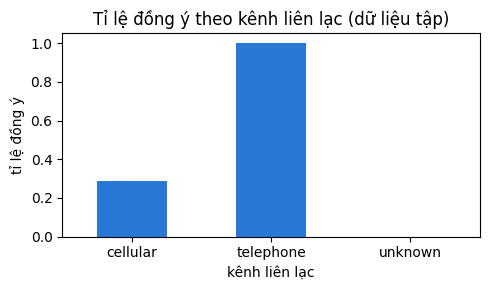

In [9]:
import matplotlib.pyplot as plt
ax = ty_le_dong_y.plot.bar(rot=0, figsize=(5, 3), color="#2a78d6", title="Tỉ lệ đồng ý theo kênh liên lạc (dữ liệu tập)")
ax.set_xlabel("kênh liên lạc"); ax.set_ylabel("tỉ lệ đồng ý")
plt.tight_layout(); plt.savefig("hinh_thu.png", dpi=200); plt.show()

## C. scikit-learn: quy trình học và đánh giá *(sổ tay, mục 4–7)*
**Mục đích:** minh họa cách giữ train/test tách biệt, chỉ học biến đổi từ train và đo hiệu quả bằng metric. Cụm TF-IDF/logistic regression phù hợp trực tiếp với hướng NLP-TF-IDF; minh họa one-hot/chuẩn hóa là phần áp dụng cho bài toán Máy học dạng bảng. Với Word2Vec–LSTM, có thể đọc phần quy trình train/test và lược qua các API scikit-learn nếu chưa cần.
`[KIẾN THỨC]` Mọi thứ “học” từ dữ liệu (từ vựng TF-IDF, trung bình để chuẩn hóa, tham số mô hình) **chỉ học trên train** bằng `fit`; tập còn lại chỉ `transform` và `predict`.
`[YÊU CẦU]` Yêu cầu sinh viên chia `phan_hoi` thành train (70%) và test (30%), **phân tầng** theo nhãn, `random_state=42`.

In [10]:
from sklearn.model_selection import train_test_split
train, test = train_test_split(
    phan_hoi, test_size=0.3, stratify=phan_hoi["nhan"], random_state=42
)  # YÊU CẦU: train_test_split(..., test_size=0.3, stratify=..., random_state=42)

In [11]:
# [TỰ KIỂM TRA]
train_ref, test_ref = train_test_split(phan_hoi, test_size=0.3, stratify=phan_hoi["nhan"], random_state=42)
assert train is not None and test is not None, "CHƯA ĐẠT: cần tạo cả train và test."
assert len(test) == 6 and (test["nhan"] == "positive").sum() == 3 and (test["nhan"] == "negative").sum() == 3, "CHƯA ĐẠT: test phải có 6 câu, mỗi nhãn 3 câu."
assert set(train.index).isdisjoint(set(test.index)) and set(train.index) | set(test.index) == set(phan_hoi.index), "CHƯA ĐẠT: train/test phải rời nhau và phủ đúng dữ liệu."
assert train.index.equals(train_ref.index) and test.index.equals(test_ref.index), "CHƯA ĐẠT: dùng đúng random_state=42 và phân tầng theo nhãn."
print("ĐẠT: split 70/30 phân tầng, không chồng lấn và tái lập được.")

ĐẠT: split 70/30 phân tầng, không chồng lấn và tái lập được.


`[YÊU CẦU]` TF-IDF và hồi quy logistic: (1) `fit_transform` trên câu của train → `X_train`; (2) chỉ `transform` câu của test → `X_test`; (3) huấn luyện `mo_hinh` trên `X_train`, dự đoán `y_du_doan` trên `X_test`.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vec = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")
X_train = vec.fit_transform(train["cau"])  # YÊU CẦU (1)
X_test = vec.transform(test["cau"])       # YÊU CẦU (2)
mo_hinh = LogisticRegression().fit(X_train, train["nhan"])  # YÊU CẦU (3): LogisticRegression().fit(...)
y_du_doan = mo_hinh.predict(X_test)       # YÊU CẦU (3)

In [13]:
# [TỰ KIỂM TRA]
expected_vocab = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b").fit(train["cau"]).vocabulary_
assert X_train is not None and X_test is not None and mo_hinh is not None, "CHƯA ĐẠT: cần tạo X_train, X_test và huấn luyện mô hình."
assert X_train.shape == (len(train), len(vec.vocabulary_)) and X_test.shape == (len(test), len(vec.vocabulary_)), "CHƯA ĐẠT: shape TF-IDF không khớp dữ liệu."
assert vec.vocabulary_ == expected_vocab, "CHƯA ĐẠT: từ vựng phải học từ TRAIN, test chỉ transform."
assert y_du_doan is not None and len(y_du_doan) == len(test) and np.array_equal(np.asarray(y_du_doan), mo_hinh.predict(X_test)), "CHƯA ĐẠT: dự đoán phải là output của mô hình trên X_test."
print("ĐẠT: từ vựng học từ train có", len(vec.vocabulary_), "token; dự đoán khớp mô hình." )

ĐẠT: từ vựng học từ train có 36 token; dự đoán khớp mô hình.


`[YÊU CẦU]` Đánh giá: tính `f1_pos` là F1 của lớp `positive` (nhãn là chuỗi nên cần `pos_label="positive"`) và in ma trận nhầm lẫn (hàng là nhãn thật).

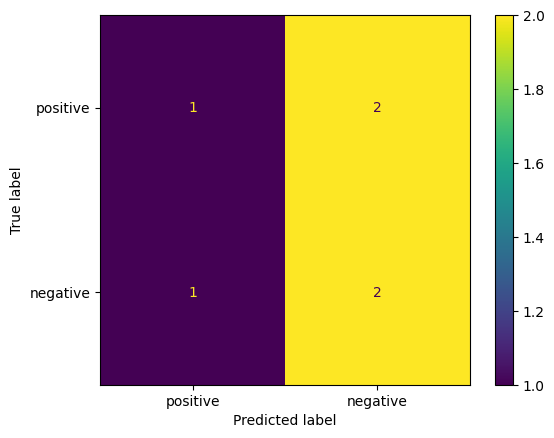

In [14]:
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

f1_pos = f1_score(
    test["nhan"], y_du_doan, pos_label="positive"
)  # YÊU CẦU: f1_score(nhãn thật, nhãn dự đoán, pos_label="positive")
ConfusionMatrixDisplay.from_predictions(
    test["nhan"], y_du_doan, labels=["positive", "negative"]
)
plt.show()

In [15]:
# [TỰ KIỂM TRA]
y_that = np.asarray(test["nhan"])
y_du_doan_arr = np.asarray(y_du_doan)
tp = int(((y_that == "positive") & (y_du_doan_arr == "positive")).sum())
fp = int(((y_that != "positive") & (y_du_doan_arr == "positive")).sum())
fn = int(((y_that == "positive") & (y_du_doan_arr != "positive")).sum())
f1_expected = 0.0 if (2 * tp + fp + fn) == 0 else 2 * tp / (2 * tp + fp + fn)
assert f1_pos is not None and np.isclose(f1_pos, f1_expected, rtol=0, atol=1e-12), "CHƯA ĐẠT: f1_pos phải khớp F1 tính từ TP, FP, FN của lớp positive."
print("ĐẠT. Thử bỏ pos_label để thấy thông báo lỗi ValueError (sổ tay, mục 7 và 10).")

ĐẠT. Thử bỏ pos_label để thấy thông báo lỗi ValueError (sổ tay, mục 7 và 10).


`[MINH HỌA]` **Pipeline** gộp hai bước trên; **xác suất và ngưỡng**: lấy cột theo `classes_`, không đoán vị trí. Thử với câu tự viết.

In [16]:
import numpy as np
from sklearn.pipeline import make_pipeline
ong = make_pipeline(TfidfVectorizer(token_pattern=r"(?u)\b\w+\b"), LogisticRegression()).fit(train["cau"], train["nhan"])
cot_neg = list(ong.classes_).index("negative")
cau_moi = ["thầy dạy hay", "phòng học nóng quá", "thầy hay đến muộn"]
p_neg = ong.predict_proba(cau_moi)[:, cot_neg]
pd.DataFrame({"câu": cau_moi, "p_negative": p_neg.round(2), "ngưỡng 0,5": np.where(p_neg >= 0.5, "negative", "positive"),
              "ngưỡng 0,4": np.where(p_neg >= 0.4, "negative", "positive")})

,câu,p_negative,"ngưỡng 0,5","ngưỡng 0,4"
0,thầy dạy hay,0.49,positive,negative
1,phòng học nóng quá,0.63,negative,negative
2,thầy hay đến muộn,0.57,negative,negative


**Ví dụ dành riêng cho dữ liệu dạng bảng** (đặc biệt liên quan tới hướng Máy học): one-hot cho cột phân loại, chuẩn hóa cho cột số. Trung bình và độ lệch chuẩn được học từ bảng đưa vào `fit`; với văn bản TF-IDF, đây là ví dụ so sánh, không phải bước bắt buộc.

In [17]:
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
tien_xu_ly = make_column_transformer((OneHotEncoder(handle_unknown="ignore"), ["job", "contact"]),
                                     (StandardScaler(), ["age", "balance"]), verbose_feature_names_out=False)
Z = tien_xu_ly.fit_transform(khach)
print(Z.shape, "| trung bình age đã học:", round(tien_xu_ly.named_transformers_["standardscaler"].mean_[0], 2))
pd.DataFrame(Z[:3], columns=tien_xu_ly.get_feature_names_out()).round(2)

(12, 11) | trung bình age đã học: 42.83


,job_admin.,job_blue-collar,job_management,job_retired,job_student,job_technician,contact_cellular,contact_telephone,contact_unknown,age,balance
0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,-1.44,-0.70
1,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,-0.54,-0.09
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.29,-0.80


`[YÊU CẦU]` (câu hỏi ngắn, trả lời vào ô này) Vì sao **không** được gọi `vec.fit_transform(test["cau"])`?

**Trả lời:** Không được gọi `vec.fit_transform(test["cau"])` vì thao tác này học lại từ vựng và trọng số TF-IDF từ tập test, khiến các cột có thể khác với khi huấn luyện. Dùng `vec.transform(test["cau"])` để giữ đúng cách mã hóa đã học từ tập train.

## D. gensim và PyTorch *(sổ tay, mục 8–9; chỉ cho hướng Word2Vec–LSTM)*
**Mục đích:** làm quen với embedding Word2Vec, padding/độ dài chuỗi, kích thước tensor của LSTM và vòng huấn luyện tối giản. Nếu làm hướng TF-IDF hoặc Máy học dạng bảng, có thể bỏ qua toàn bộ phần D.
[TÙY CHỌN] Phần D cần `gensim` và `torch`. Cài dependencies trong một môi trường riêng trước khi chạy; notebook chỉ kiểm tra và báo package còn thiếu, không tự cài hay truy cập mạng.

In [18]:
%pip install gensim==4.4.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 55.6 MB/s  0:00:00 eta 0:00:01


In [19]:
# Phần D là tùy chọn, chỉ dành cho đồ án Word2Vec–LSTM.
# Hãy cài dependencies trong môi trường riêng trước khi chạy; notebook không tự cài package.
import importlib.util
thieu = [ten for ten in ("gensim", "torch") if importlib.util.find_spec(ten) is None]
if thieu:
    raise ModuleNotFoundError("Phần D cần cài sẵn các package: " + ", ".join(thieu) + ". Có thể bỏ qua phần D nếu không làm đồ án Word2Vec–LSTM.")
import gensim
from gensim.models import Word2Vec
import torch, torch.nn as nn
print("gensim", gensim.__version__, "| torch", torch.__version__)

gensim 4.4.0 | torch 2.14.1+cpu


`[YÊU CẦU]` Huấn luyện Word2Vec trên 20 câu (đầu vào là **danh sách các câu, mỗi câu là danh sách token**). Với dữ liệu nhỏ như vậy, vector chưa có ý nghĩa; mục đích chỉ là tập lệnh.

In [20]:
cau_tach = [cau.split() for cau in phan_hoi["cau"]]     # YÊU CẦU: danh sách token của từng câu (dùng .split())
w2v = Word2Vec(cau_tach, vector_size=20, window=2, min_count=1, sg=1, epochs=50, seed=42, workers=1)
print(len(w2v.wv), w2v.wv["thầy"].shape, w2v.wv.most_similar("thầy", topn=2))

51 (20,) [('ích', 0.576021134853363), ('dõi', 0.49003538489341736)]


In [21]:
# [TỰ KIỂM TRA]
assert isinstance(cau_tach[0], list) and w2v.wv["thầy"].shape == (20,), "CHƯA ĐẠT: mỗi câu phải là danh sách token."
print("ĐẠT.")

ĐẠT.


`[MINH HỌA]` Mã hóa câu thành dãy chỉ số (đệm bằng 0 cho đủ 6 token) và theo dõi **kích thước tensor** qua từng lớp.

In [22]:
tu_vung = ["<pad>", "<unk>"] + sorted({t for c in cau_tach for t in c})
chi_so = {t: i for i, t in enumerate(tu_vung)}
def ma_hoa(cau, n=6):
    ids = [chi_so.get(t, 1) for t in cau.split()][:n]
    return ids + [0] * (n - len(ids)), len(ids)
X = torch.tensor([ma_hoa(c)[0] for c in phan_hoi["cau"]])
L = torch.tensor([ma_hoa(c)[1] for c in phan_hoi["cau"]])
y = torch.tensor((phan_hoi["nhan"] == "positive").astype(int).to_numpy())
print("X:", tuple(X.shape), X.dtype, "| câu đầu:", X[0].tolist(), "độ dài", int(L[0]))

X: (20, 6) torch.int64 | câu đầu: [37, 7, 29, 12, 0, 0] độ dài 4


`[YÊU CẦU]` Hoàn thành hai dòng trong `forward`: (1) `e = self.nhung(x)`; (2) trả về `self.ra(h[-1])`. Sau đó chạy ô kiểm tra kích thước.

In [23]:
torch.manual_seed(0)
class MoHinhNho(nn.Module):
    def __init__(self):
        super().__init__()
        self.nhung = nn.Embedding(len(tu_vung), 8, padding_idx=0)
        self.lstm = nn.LSTM(8, 16, batch_first=True)
        self.ra = nn.Linear(16, 2)
    def forward(self, x, do_dai):
        e = self.nhung(x)      # YÊU CẦU (1)
        _, (h, _) = self.lstm(nn.utils.rnn.pack_padded_sequence(e, do_dai, batch_first=True, enforce_sorted=False))
        return self.ra(h[-1])   # YÊU CẦU (2)
mh = MoHinhNho()

In [24]:
# [TỰ KIỂM TRA]
try:
    ra = mh(X[:4], L[:4])
except Exception:
    ra = None
assert ra is not None and tuple(ra.shape) == (4, 2), "CHƯA ĐẠT: đầu ra phải có kích thước (4, 2)."
print("ĐẠT: (4, 6) → Embedding (4, 6, 8) → LSTM h (1, 4, 16) → Linear (4, 2)")

ĐẠT: (4, 6) → Embedding (4, 6, 8) → LSTM h (1, 4, 16) → Linear (4, 2)


`[MINH HỌA]` Vòng huấn luyện bốn dòng (xóa gradient → mất mát → lan truyền ngược → cập nhật). Mất mát trên 20 câu phải giảm dần; mô hình học thuộc dữ liệu nhỏ này, nên điều đó **không** chứng tỏ mô hình tốt.

In [25]:
toi_uu = torch.optim.Adam(mh.parameters(), lr=0.01)
ham_mat_mat = nn.CrossEntropyLoss()
for buoc in range(1, 61):
    mh.train()
    toi_uu.zero_grad()
    mat_mat = ham_mat_mat(mh(X, L), y)
    mat_mat.backward()
    toi_uu.step()
    if buoc % 20 == 0:
        print("bước", buoc, "| mất mát", round(mat_mat.item(), 4))
mh.eval()
with torch.no_grad():
    print("Độ chính xác trên chính 20 câu train:", (mh(X, L).argmax(1) == y).float().mean().item())

bước 20 | mất mát 0.151
bước 40 | mất mát 0.0018
bước 60 | mất mát 0.0005
Độ chính xác trên chính 20 câu train: 1.0


## Kết thúc
- [X] Chạy *Runtime → Restart session and run all*: mọi ô `[TỰ KIỂM TRA]` trong các phần đã chọn in **ĐẠT**.
- [X] Làm A và B; chọn nội dung C theo đồ án. Chỉ làm D nếu theo Word2Vec–LSTM.
- [X] Mở **Sổ tay thư viện**, đọc mục 10 (đọc thông báo lỗi) nếu cần.
- [X] Notebook này là tài liệu chuẩn bị độc lập: không nộp và không thay thế các notebook của đồ án. Bắt đầu đồ án với notebook tuần 1.